# Solar flares 2021-2026: how did activity and the share of strong flares evolve?

**Research question:** How did the monthly number of flares evolve from February 2021 up to and including February 2026
(use all rows of the file), and did the share of strong flares change over the years?

**Data:** STIX flare list (X-ray telescope on ESA's Solar Orbiter), `data/stix_flarelist.csv`.

**How to read this notebook.** One step per cell, top to bottom. Every number in the text is computed by the cell above it,
nothing is typed in by hand. Cells that can break contain an `assert` with a message, so a failure tells you which assumption
about the data no longer holds. The last two sections check the result against `ground_truth.json` and show where the
LLM system currently stands.

| Section | What it does |
|---|---|
| 1 | Load the data and check its quality |
| 2 | Monthly number of flares (question part 1) |
| 3 | Share of strong flares per year (question part 2) |
| 4 | How much does the answer depend on the definition of "strong"? |
| 5 | Answer in words (generated from the numbers) |
| 6 | Cross-check with the ground truth |
| 7 | Status of the LLM system |

## 0. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent   # started from notebooks/ or from the project folder
assert (ROOT / "data" / "stix_flarelist.csv").exists(), f"data file not found below {ROOT}"
sys.path.insert(0, str(ROOT))

# two colours that stay distinguishable for colour-blind readers; everything else is grey
BLUE, ORANGE, INK, GREY = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8985"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False,
})

## 1. Load the data and check its quality

In [2]:
df = pd.read_csv(ROOT / "data" / "stix_flarelist.csv", low_memory=False)
print(f"{len(df):,} rows x {df.shape[1]} columns")
df[["flare_id", "start_UTC", "peak_UTC", "4-10 keV", "att_in", "visible_from_earth",
    "GOES_class_time_of_flare", "goes_estimated_mean_class"]].head(3)

33,076 rows x 40 columns


,flare_id,start_UTC,peak_UTC,4-10 keV,att_in,visible_from_earth,GOES_class_time_of_flare,goes_estimated_mean_class
0,2102140144,2021-02-14T01:41:06.670,2021-02-14T01:44:14.670,1983,False,NaN,A,B6
1,2102141324,2021-02-14T13:21:34.741,2021-02-14T13:24:54.741,1855,False,NaN,A,B6
2,2102141936,2021-02-14T19:34:46.779,2021-02-14T19:36:46.779,1215,False,NaN,A,B5


In [3]:
# start_UTC is text (ISO 8601 with milliseconds): parse it explicitly instead of letting pandas guess
df["start"] = pd.to_datetime(df["start_UTC"], format="ISO8601")
assert df["start"].notna().all(), "some start_UTC values could not be parsed"
df["year"] = df["start"].dt.year
df["month"] = df["start"].dt.to_period("M").dt.to_timestamp()      # first day of the month
print("first flare:", df["start"].min(), "| last flare:", df["start"].max())

first flare: 2021-02-14 01:41:06.670000 | last flare: 2026-02-28 22:01:02.764000


In [4]:
quality = pd.DataFrame([
    ("rows", len(df), "all rows are used, none is dropped"),
    ("duplicate flare_id", int(df["flare_id"].duplicated().sum()), "ids are unique"),
    ("start_UTC not parseable", int(df["start"].isna().sum()), "time column is usable"),
    ("GOES_class_time_of_flare missing", int(df["GOES_class_time_of_flare"].isna().sum()),
     "measured GOES class exists only for part of the flares"),
    ("goes_estimated_mean_class missing", int(df["goes_estimated_mean_class"].isna().sum()),
     "STIX's own class estimate exists for every flare"),
    ("flares seen from Earth side", int((df["visible_from_earth"] == True).sum()), "GOES can only see these"),
    ("flares on the far side", int((df["visible_from_earth"] == False).sum()), "no Earth instrument sees these"),
    ("position unknown (visible_from_earth empty)", int(df["visible_from_earth"].isna().sum()), "imaging failed"),
    ("attenuator inserted (att_in)", int(df["att_in"].sum()), "counts are reduced for these"),
], columns=["check", "value", "meaning"])
quality

,check,value,meaning
0,rows,33076,"all rows are used, none is dropped"
1,duplicate flare_id,0,ids are unique
2,start_UTC not parseable,0,time column is usable
3,GOES_class_time_of_flare missing,620,measured GOES class exists only for part of th...
4,goes_estimated_mean_class missing,0,STIX's own class estimate exists for every flare
5,flares seen from Earth side,15585,GOES can only see these
6,flares on the far side,15015,no Earth instrument sees these
7,position unknown (visible_from_earth empty),2476,imaging failed
8,attenuator inserted (att_in),263,counts are reduced for these


**What matters for the question.** The file starts on 14 February 2021, so February 2021 and the year 2021 are *partial*;
2026 contains only January and February. The monthly and yearly numbers below mark these periods explicitly.
About half of the flares were seen from the far side of the Sun, where GOES (Earth orbit) is blind, so a class taken from
GOES is not available or not meaningful for them. This is why section 3 uses STIX's own estimate.

## 2. Monthly number of flares
Flares are counted by the month of their start time. Months without any flare would be kept as zero.

In [5]:
monthly = df.groupby("month").size().asfreq("MS", fill_value=0)       # no month may be missing
n_months = len(monthly)
busiest = monthly.idxmax()
print(f"{n_months} months, from {monthly.index[0]:%Y-%m} to {monthly.index[-1]:%Y-%m}")
print(f"busiest month: {busiest:%Y-%m} with {monthly.max():,} flares | quietest full month: {monthly.iloc[1:].idxmin():%Y-%m} with {monthly.iloc[1:].min()} (Feb 2021 is partial)")
assert n_months == 61, f"expected 61 months (Feb 2021 .. Feb 2026), got {n_months}"
assert monthly.sum() == len(df), "monthly counts do not add up to the number of rows"

61 months, from 2021-02 to 2026-02
busiest month: 2024-09 with 1,724 flares | quietest full month: 2021-04 with 9 (Feb 2021 is partial)


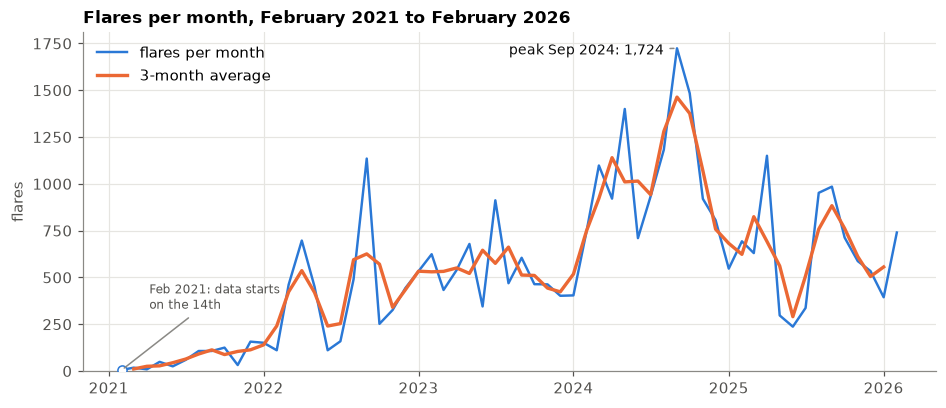

In [6]:
rolling = monthly.rolling(3, center=True).mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, color=BLUE, lw=1.6, label="flares per month")
ax.plot(rolling.index, rolling.values, color=ORANGE, lw=2.2, label="3-month average")
ax.scatter(monthly.index[:1], monthly.values[:1], s=36, facecolor="white", edgecolor=BLUE, zorder=3)
ax.annotate("Feb 2021: data starts\non the 14th", (monthly.index[0], monthly.iloc[0]), xytext=(18, 40),
            textcoords="offset points", fontsize=8, color="#52514e", arrowprops=dict(arrowstyle="-", color=GREY))
ax.annotate(f"peak {busiest:%b %Y}: {monthly.max():,}", (busiest, monthly.max()), xytext=(-110, -4),
            textcoords="offset points", fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=GREY))
ax.set_ylabel("flares"); ax.set_title("Flares per month, February 2021 to February 2026")
ax.legend(loc="upper left"); ax.set_ylim(0)
plt.show()

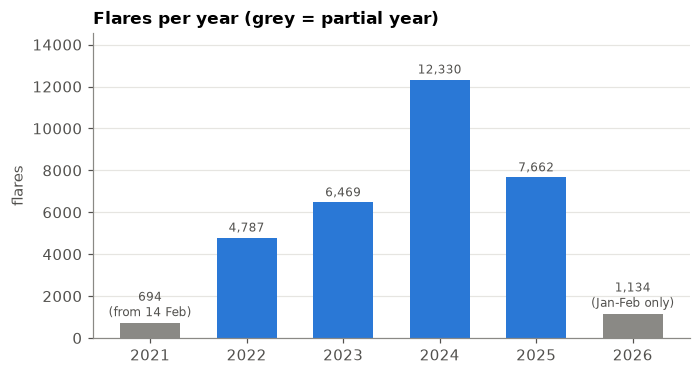

,flares
year,
2021,694
2022,4787
2023,6469
2024,12330
2025,7662
2026,1134


In [7]:
yearly = df.groupby("year").size()
partial = {2021: "from 14 Feb", 2026: "Jan-Feb only"}
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(yearly.index.astype(str), yearly.values, color=[GREY if y in partial else BLUE for y in yearly.index], width=0.62)
for b, y, v in zip(bars, yearly.index, yearly.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 150, f"{v:,}" + (f"\n({partial[y]})" if y in partial else ""),
            ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_ylim(0, yearly.max() * 1.18); ax.set_ylabel("flares"); ax.set_title("Flares per year (grey = partial year)")
ax.grid(axis="x", visible=False)
plt.show()
yearly.to_frame("flares")

## 3. Share of strong flares per year
**Definition used here (assumption, stated explicitly):** a flare is *strong* if its GOES-equivalent class estimated by STIX
(`goes_estimated_mean_class`) starts with **M or X**. This column exists for every flare, also for the far side.
Section 4 tests how much the answer depends on this choice.

In [8]:
df["strong"] = df["goes_estimated_mean_class"].str[0].isin(["M", "X"])
n_strong = int(df["strong"].sum())
by_year = df.groupby("year")["strong"].agg(n="size", strong="sum")
by_year["pct"] = (by_year["strong"] / by_year["n"] * 100).round(2)

def wilson(k, n, z=1.96):
    # 95 % interval for a share; honest about small samples (2021, 2026)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half) * 100, (centre + half) * 100

by_year["lo"], by_year["hi"] = zip(*[wilson(k, n) for k, n in zip(by_year["strong"], by_year["n"])])
print(f"{n_strong:,} strong flares in total ({n_strong / len(df):.1%} of all)")
by_year.round(2)

1,637 strong flares in total (4.9% of all)


,n,strong,pct,lo,hi
year,,,,,
2021,694,29,4.18,2.92,5.94
2022,4787,247,5.16,4.57,5.82
2023,6469,349,5.39,4.87,5.97
2024,12330,636,5.16,4.78,5.56
2025,7662,296,3.86,3.45,4.32
2026,1134,80,7.05,5.70,8.69


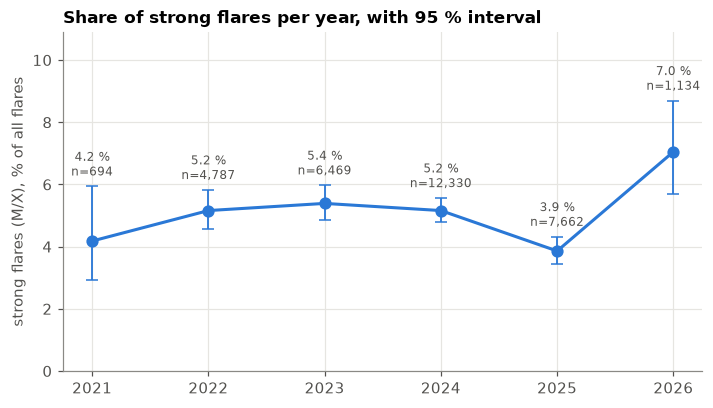

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4))
x = by_year.index.astype(str)
ax.errorbar(x, by_year["pct"], yerr=[by_year["pct"] - by_year["lo"], by_year["hi"] - by_year["pct"]],
            color=BLUE, lw=2, marker="o", ms=7, capsize=4, elinewidth=1.2)
for xi, (_, r) in zip(x, by_year.iterrows()):
    ax.text(xi, r["hi"] + 0.35, f"{r['pct']:.1f} %\nn={int(r['n']):,}", ha="center", fontsize=8, color="#52514e")
ax.set_ylim(0, by_year["hi"].max() + 2.2)
ax.set_ylabel("strong flares (M/X), % of all flares")
ax.set_title("Share of strong flares per year, with 95 % interval")
plt.show()

In [10]:
# the question: does the share rise from each year to the next across the FULL years 2022-2025?
full = by_year.loc[2022:2025, "pct"]
steps = full.diff().dropna()
increasing = bool((steps > 0).all())
print("share 2022-2025:", full.to_dict())
print("change from year to year:", steps.round(2).to_dict())
print("rises every full year:", increasing)

share 2022-2025: {2022: 5.16, 2023: 5.39, 2024: 5.16, 2025: 3.86}
change from year to year: {2023: 0.23, 2024: -0.23, 2025: -1.3}
rises every full year: False


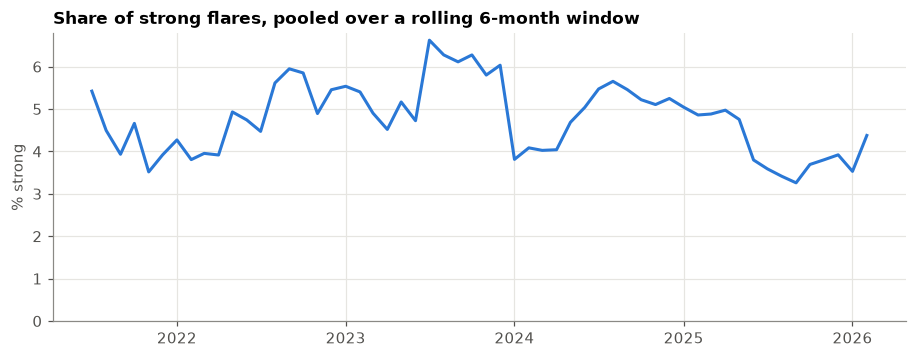

In [11]:
# within-year view: pooled share over a 6-month window (a monthly share alone is too noisy for 2021)
pooled = df.groupby("month")["strong"].agg(["sum", "size"]).asfreq("MS", fill_value=0)
share6 = pooled["sum"].rolling(6).sum() / pooled["size"].rolling(6).sum() * 100
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(share6.index, share6.values, color=BLUE, lw=2)
ax.set_ylim(0); ax.set_ylabel("% strong"); ax.set_title("Share of strong flares, pooled over a rolling 6-month window")
plt.show()

## 4. Does the answer depend on the definition of "strong"?
Three variants. They differ in *which column* defines the class and *which flares* are included.
- **A (used above):** STIX estimate `goes_estimated_mean_class`, all flares.
- **B:** class measured by GOES (`GOES_class_time_of_flare`), all flares that have one. For far-side flares this is the GOES
  background of the Earth side, not the flare itself.
- **C:** like A, but only flares seen from the Earth side.

In [12]:
variants = pd.DataFrame({
    "A  STIX estimate, all": df.groupby("year")["strong"].mean() * 100,
    "B  GOES measured, rows with a class": df.dropna(subset=["GOES_class_time_of_flare"])
        .assign(s=lambda d: d["GOES_class_time_of_flare"].str[0].isin(["M", "X"])).groupby("year")["s"].mean() * 100,
    "C  STIX estimate, Earth side only": df[df["visible_from_earth"] == True].groupby("year")["strong"].mean() * 100,
}).round(2)
variants

,"A STIX estimate, all","B GOES measured, rows with a class","C STIX estimate, Earth side only"
year,,,
2021,4.18,3.49,2.80
2022,5.16,3.63,4.22
2023,5.39,4.90,4.12
2024,5.16,10.15,5.20
2025,3.86,4.43,4.24
2026,7.05,10.63,3.43


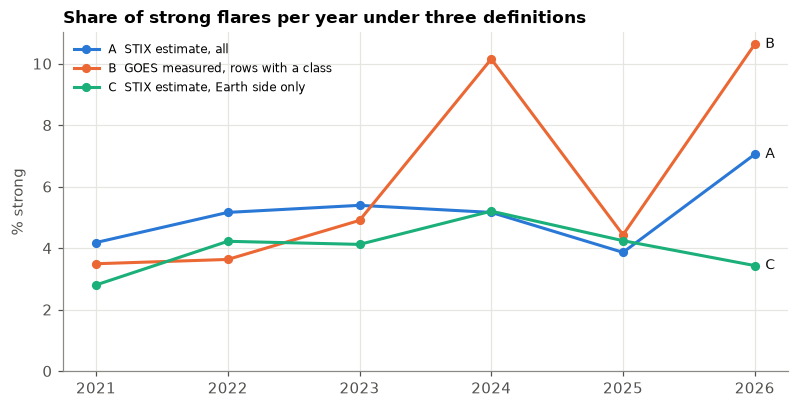

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for (name, s), colour in zip(variants.items(), [BLUE, ORANGE, "#1baf7a"]):
    ax.plot(s.index.astype(str), s.values, color=colour, lw=2, marker="o", ms=5, label=name)
    ax.text(len(s) - 1 + 0.08, s.iloc[-1], name[:1], color=INK, fontsize=9, va="center")
ax.set_ylim(0); ax.set_ylabel("% strong"); ax.set_title("Share of strong flares per year under three definitions")
ax.legend(loc="upper left", fontsize=8)
plt.show()

In [14]:
inc = {name[:1]: bool((s.loc[2022:2025].diff().dropna() > 0).all()) for name, s in variants.items()}
print("rises every full year 2022-2025, per variant:", inc)

rises every full year 2022-2025, per variant: {'A': False, 'B': False, 'C': False}


**Spacecraft distance as a caveat.** STIX counts more photons when Solar Orbiter is closer to the Sun, so the number of
*detected* flares and the class estimate can depend on the orbit, not only on the Sun.

In [15]:
df.groupby("year").agg(flares=("flare_id", "size"), median_distance_AU=("solo_position_AU_distance", "median"),
                       min_AU=("solo_position_AU_distance", "min"), max_AU=("solo_position_AU_distance", "max")).round(2)

,flares,median_distance_AU,min_AU,max_AU
year,,,,
2021,694,0.80,0.50,1.02
2022,4787,0.66,0.29,1.02
2023,6469,0.79,0.29,0.95
2024,12330,0.69,0.29,0.95
2025,7662,0.63,0.29,0.95
2026,1134,0.59,0.30,0.85


## 5. The answer in words (generated from the numbers above)

In [16]:
peak_year = yearly.idxmax()
lo_y, hi_y = full.idxmin(), full.idxmax()
text = f'''
**Flares per month.** Between February 2021 and February 2026 the catalogue holds {len(df):,} flares in {n_months} months.
Activity rose from {yearly[2021]:,} flares in 2021 (from 14 Feb) to a maximum of {yearly[peak_year]:,} in {peak_year}; the busiest
month is {busiest:%B %Y} with {monthly.max():,} flares. In 2025 the yearly count fell to {yearly[2025]:,}.

**Share of strong flares.** Using STIX's own class estimate, {n_strong:,} flares ({n_strong / len(df):.1%}) are strong (M/X).
The yearly share lies between {full.min():.1f} % ({lo_y}) and {full.max():.1f} % ({hi_y}) in the full years 2022-2025.
It does {'' if increasing else 'not '}rise from each year to the next, so the share of strong flares
{'grew steadily' if increasing else 'did not grow steadily'}; the 95 % intervals in the chart show how much of the year-to-year
difference can be sampling noise.

**Robustness.** The statement "the share rises every full year" is {inc['A']} for the STIX estimate (A), {inc['B']} for the
GOES-measured class (B) and {inc['C']} for Earth-side flares only (C): the conclusion does not depend on the definition.
The level does: in 2024 the share is {variants.iloc[:, 0][2024]:.1f} % under A, {variants.iloc[:, 1][2024]:.1f} % under B and
{variants.iloc[:, 2][2024]:.1f} % under C.

**Limits.** 2021 and 2026 are partial years. Detection depends on the distance of the spacecraft. The class of far-side flares
is only an estimate.
'''
from IPython.display import Markdown
Markdown(text)


**Flares per month.** Between February 2021 and February 2026 the catalogue holds 33,076 flares in 61 months.
Activity rose from 694 flares in 2021 (from 14 Feb) to a maximum of 12,330 in 2024; the busiest
month is September 2024 with 1,724 flares. In 2025 the yearly count fell to 7,662.

**Share of strong flares.** Using STIX's own class estimate, 1,637 flares (4.9%) are strong (M/X).
The yearly share lies between 3.9 % (2025) and 5.4 % (2023) in the full years 2022-2025.
It does not rise from each year to the next, so the share of strong flares
did not grow steadily; the 95 % intervals in the chart show how much of the year-to-year
difference can be sampling noise.

**Robustness.** The statement "the share rises every full year" is False for the STIX estimate (A), False for the
GOES-measured class (B) and False for Earth-side flares only (C): the conclusion does not depend on the definition.
The level does: in 2024 the share is 5.2 % under A, 10.2 % under B and
5.2 % under C.

**Limits.** 2021 and 2026 are partial years. Detection depends on the distance of the spacecraft. The class of far-side flares
is only an estimate.


## 6. Cross-check with the ground truth
`ground_truth.json` was computed independently by `step0/facts.py`. The same checker that grades the LLM runs
(`src/checker.py`) compares it with the numbers of this notebook, in the exact format the LLM has to print as `RESULTS_JSON`.

In [17]:
from src.checker import check, score

results_json = {
    "n_months": int(n_months),
    "busiest_month": f"{busiest:%Y-%m}",
    "busiest_month_count": int(monthly.max()),
    "flares_per_year": {str(k): int(v) for k, v in yearly.items()},
    "n_strong": n_strong,
    "pct_strong_per_year": {str(k): float(v) for k, v in by_year["pct"].items()},
    "strong_share_increasing": increasing,
}
checks = check(results_json)
print(json.dumps(checks, indent=1))
assert score(checks) == 1.0, "this notebook disagrees with ground_truth.json - one of the two is wrong"
print("reference report matches the ground truth: 7/7")

{
 "n_months": true,
 "busiest_month": true,
 "busiest_month_count": true,
 "flares_per_year": true,
 "n_strong": true,
 "pct_strong_per_year": true,
 "strong_share_increasing": true
}
reference report matches the ground truth: 7/7


## 7. Status of the LLM system
Same question, but answered by the local model. Read from `results/versions.csv` (rebuild it with `python analyze.py`);
the full history with what changed in each experiment is in `PERFORMANCE_LOG.md`.

In [18]:
vpath = ROOT / "results" / "versions.csv"
if vpath.exists():
    v = pd.read_csv(vpath)
    v = v[v["version"].isin(["v1", "2a", "2b", "2c"]) & (v["version"] == v["level"].replace("baseline", "v1"))]
    status = v.groupby("experiment").agg(runs=("seed", "size"), ran=("exit_code", lambda s: int((s == 0).sum())),
                                         depth=("funnel_depth", "mean"), facts=("fact_score", "mean"))
    display(status.round(2))
else:
    print("results/versions.csv not found - run `python analyze.py` first")

,runs,ran,depth,facts
experiment,,,,
E01_baseline_schema,5,0,2.0,0.0
